# Quick start: TRAM-DAG on JAX

This notebook shows the complete workflow with the JAX engine on the mixed example of the paper (section 6.2):
two continuous variables `x1`, `x2` and an ordinal `x3` with 4 levels.

1. simulate data
2. **configure the DAG in one line** (or visually with `cfg.edit()`)
3. fit all node models jointly (seconds instead of minutes)
4. diagnostics: losses, coefficients, latents
5. sampling: observational, interventional, counterfactual

Install: `pip install "tramdag[ui]"` (CPU) or additionally `pip install "jax[cuda12]"` for NVIDIA GPUs.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from tramdag import TramDagConfig, TramDagModel


def dgp(n, do_x1=None, do_x2=None, seed=None):
    rng = np.random.default_rng(seed)
    x1 = np.where(rng.random(n) < 0.5, rng.normal(0.25, 0.1, n), rng.normal(0.73, 0.05, n)) if do_x1 is None else np.full(n, do_x1)
    x2 = (rng.logistic(size=n) - 2 * x1) / 5 if do_x2 is None else np.full(n, do_x2)
    h = np.array([-2.0, 0.42, 1.02]) + 0.2 * x1[:, None] + x2[:, None]   # P(x3 <= k) = sigmoid(theta_k + 0.2 x1 + x2)
    x3 = (rng.logistic(size=n)[:, None] > h).sum(1)
    return pd.DataFrame({"x1": x1, "x2": x2, "x3": x3})


df = dgp(100_000, seed=42)
train_df, tmp = train_test_split(df, test_size=0.2, random_state=42)
val_df, test_df = train_test_split(tmp, test_size=0.5, random_state=42)
df.describe().round(3)

,x1,x2,x3
count,100000.000,100000.000,100000.000
mean,0.491,-0.197,1.591
std,0.252,0.375,1.026
min,-0.232,-2.792,0.000
25%,0.251,-0.429,1.000
50%,0.604,-0.198,1.000
75%,0.730,0.033,3.000
max,0.964,2.078,3.000


## 2. Configuration

Edges are written as `parent -> child [term]`:

| syntax | meaning |
|---|---|
| `x1 -> x2` | linear shift `ls(x1)` (default, interpretable coefficient) |
| `x1 -> x2 [cs]` | complex shift: a neural network `f(x1)` |
| `x1 -> x2 [ci]` | complex intercept: the whole transformation function depends on `x1` |
| `x1, x2 -> x3` | two separate edges |
| `(x1, x2) -> x3 [cs]` | interaction: one network `f(x1, x2)` |
| `x2 -> x3 [cs, model=MLP(32,32,tanh)]` | choose the network |

Data types and the number of levels of ordinal variables are inferred from the data (`x3` takes the values 0..3).
The variable order does not matter, the configuration is written in causal order.

In [2]:
cfg = TramDagConfig.from_dataframe(
    train_df,
    edges="x1 -> x2; x1, x2 -> x3",
    experiment_dir="quickstart_experiment",
    training={"epochs": 200, "batch_size": 1000, "learning_rate": 0.01},
)
cfg.describe()

node  data type       levels  transformation function
--------------------------------------------------------------------------
x1    continous               h(x1) = SI
x2    continous               h(x2 | x1) = SI + ls(x1)
x3    ordinal_Xn_Yo   4       h(x3 | x1, x2) = SI + ls(x1) + ls(x2)


/home/donald_duck/repos/TramDag/tramdag/TramDagConfig.py:495: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


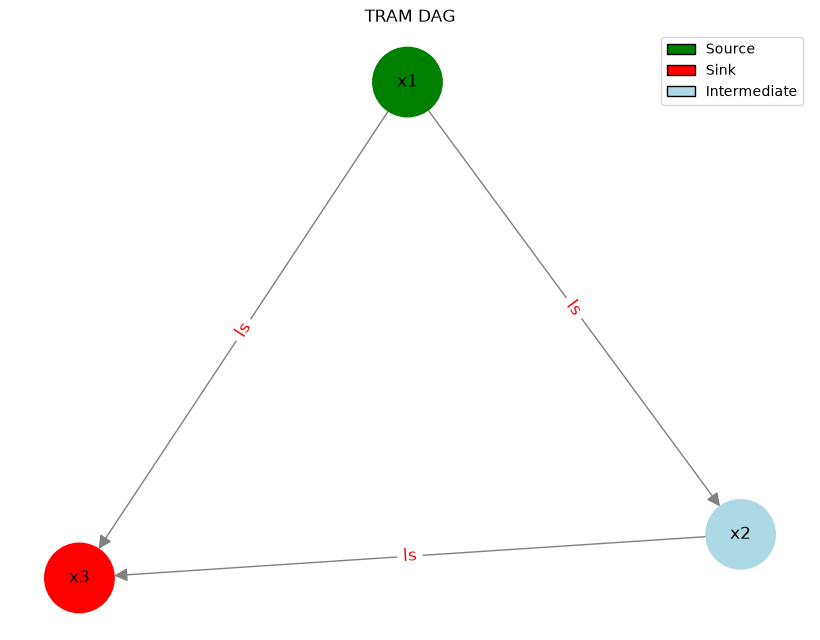

In [3]:
cfg.plot_dag(causal_order=True)

### Visual editor (optional)

`cfg.edit()` opens an editor in the notebook: drag from the dot on the right of a node onto another node to add an edge,
click an edge to choose *linear shift / complex shift / complex intercept*, an interaction group and the network,
click a node to set its data type and levels. Errors (cycles, invalid interaction groups, missing levels, ...)
are shown while you edit; **Save** writes `configuration.json`.

Outside of notebooks the same editor runs in the browser: `python -m tramdag.ui quickstart_experiment/configuration.json`.

In [4]:
cfg.edit()

## 3. Fit

All nodes are trained jointly in one compiled JAX program; the training defaults come from the configuration.

In [5]:
model = TramDagModel.from_config(cfg, seed=0)
model.fit(train_df, val_df)

[INFO] Node x1 already trained for 200 epochs. Skipping.
[INFO] Node x2 already trained for 200 epochs. Skipping.
[INFO] Node x3 already trained for 200 epochs. Skipping.


## 4. Diagnostics

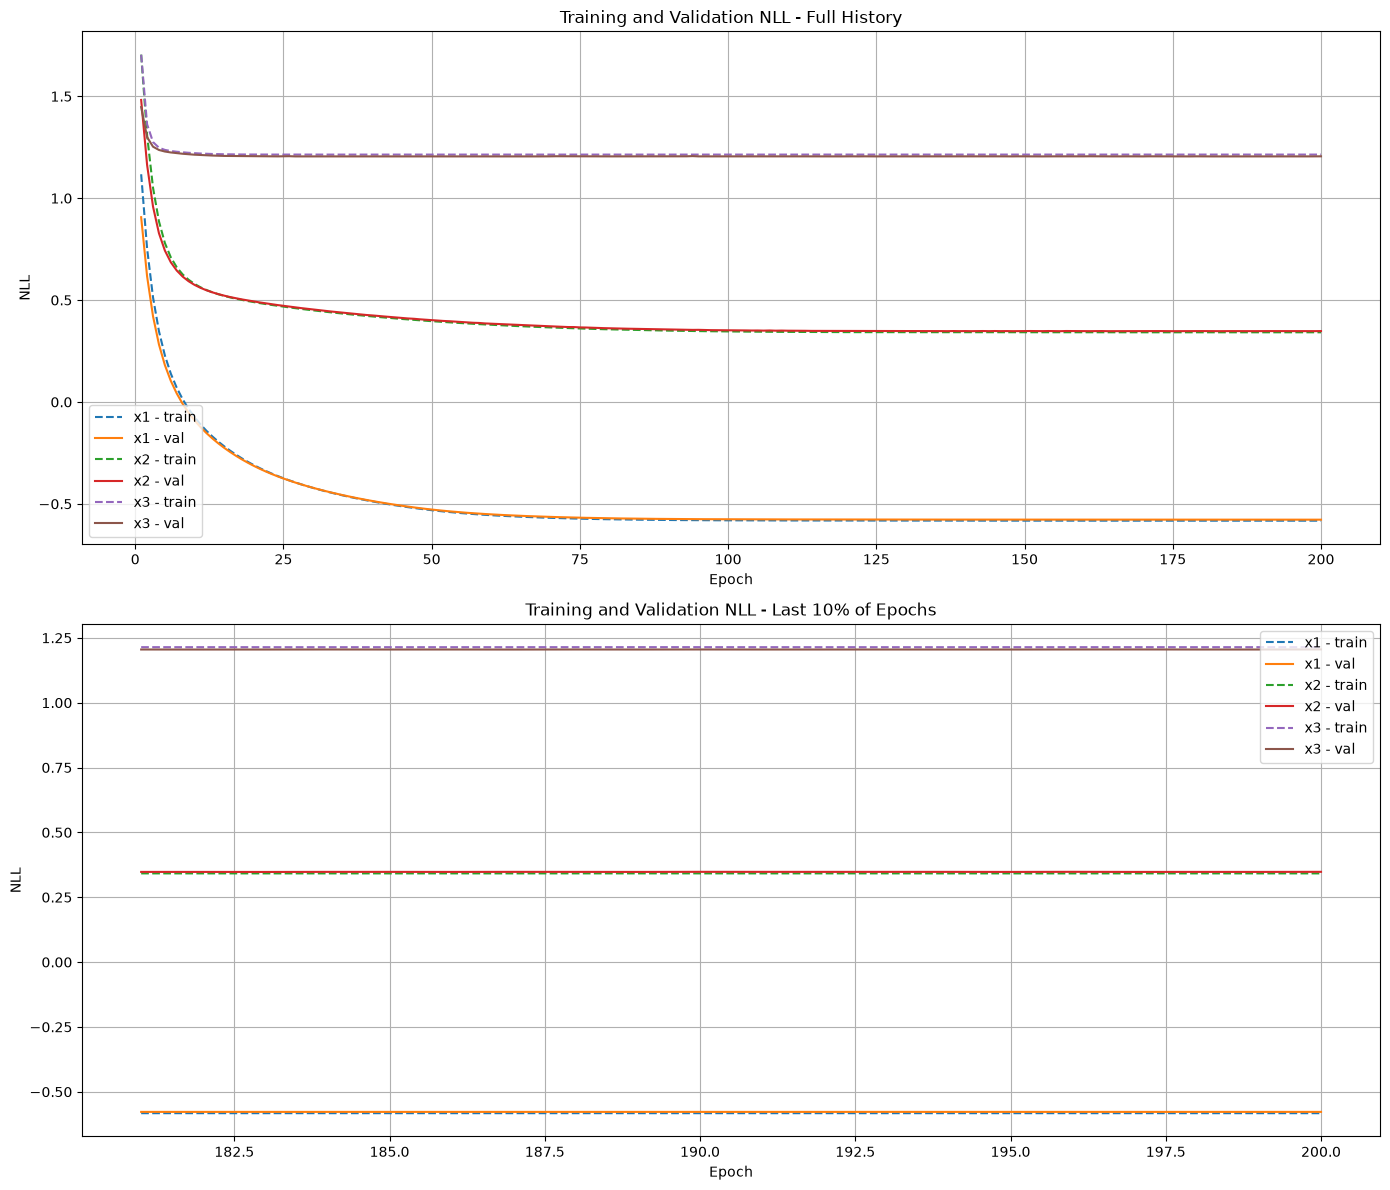

In [6]:
model.plot_loss_history()

In [7]:
# true values: ls(x1) on x2 = 2 ; on x3 the DGP uses P(x3<=k) = sigmoid(theta_k + 0.2 x1 + x2) -> shifts -0.2 and -1
model.coefficients()

,node,term,input,coefficient
0,x2,ls,x1,1.924505
1,x3,ls,x1,-0.131142
2,x3,ls,x2,-1.010549


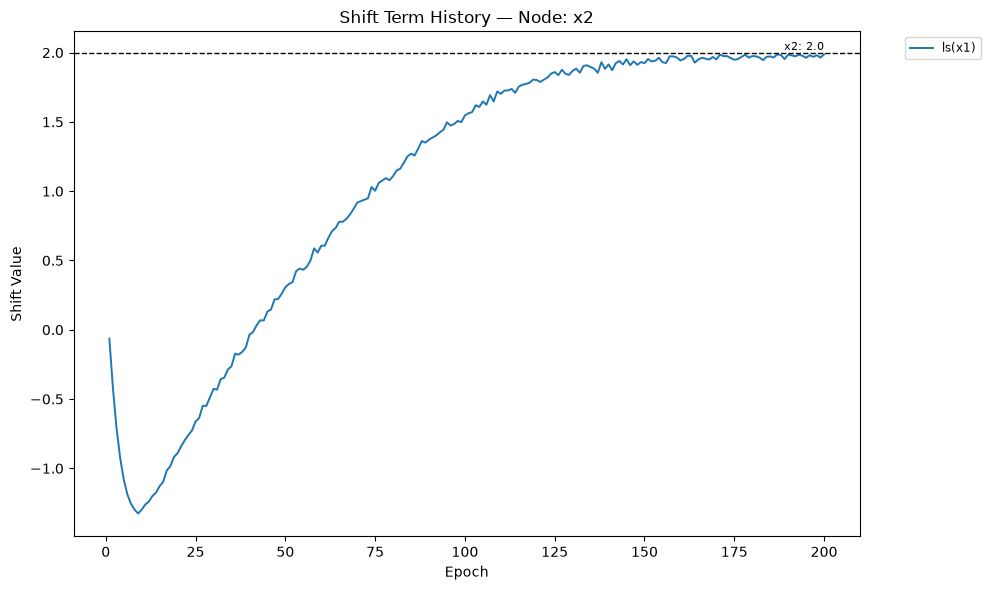

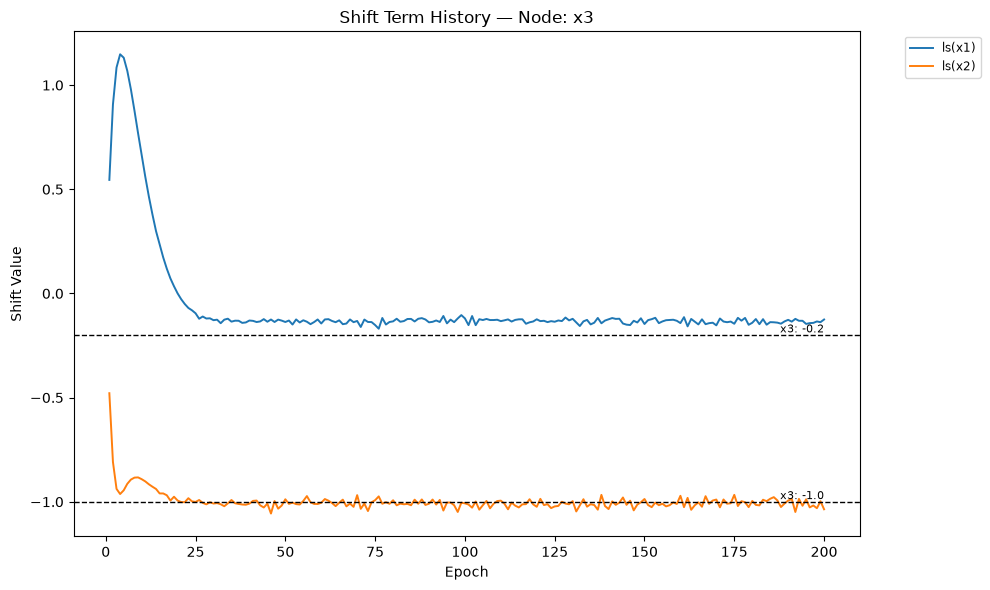

In [8]:
model.plot_linear_shift_history(ref_lines={'x2': [2.0], 'x3': [-0.2, -1.0]})

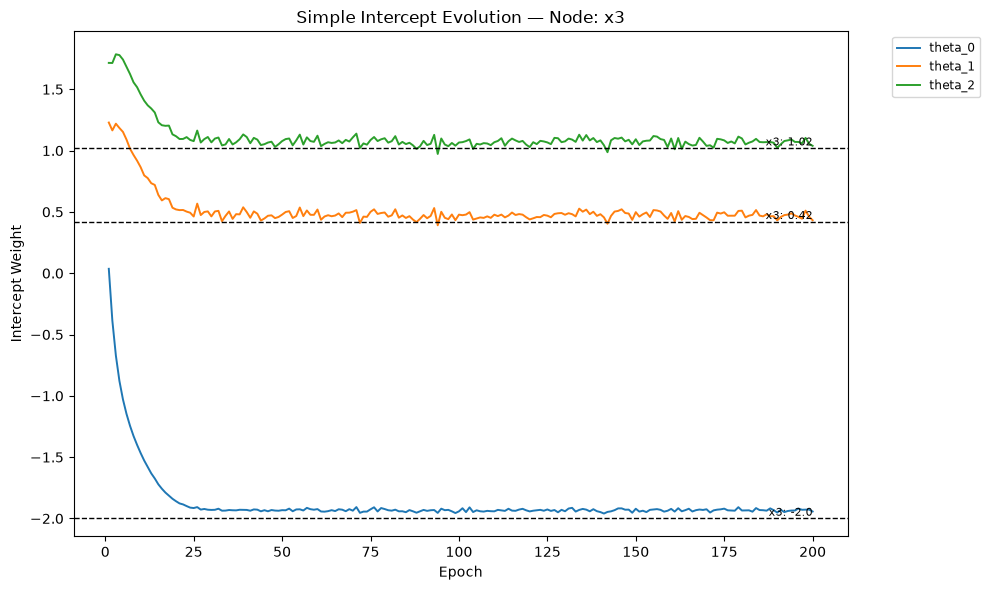

In [9]:
model.plot_simple_intercepts_history(node='x3', ref_lines={'x3': [-2.0, 0.42, 1.02]})

In [10]:
model.nll(test_df)

{'x1': -0.5834153294563293, 'x2': 0.3480115532875061, 'x3': 1.2117769718170166}

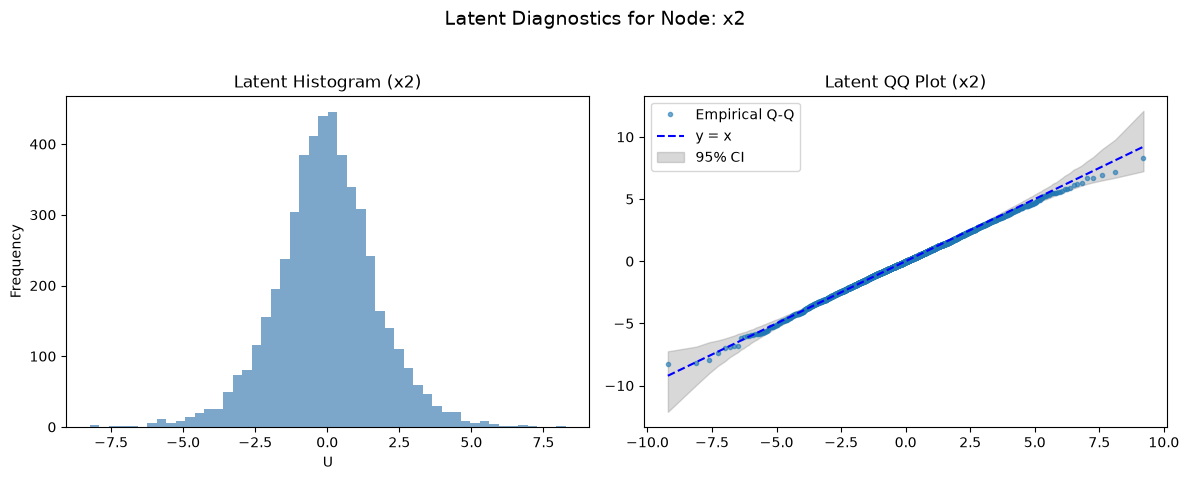

In [11]:
model.plot_latents(train_df.iloc[:5000], variable='x2')

## 5. Sampling

### Observational

[INFO] x1: standard logistic latents


[INFO] x2: standard logistic latents
[INFO] x3: standard logistic latents


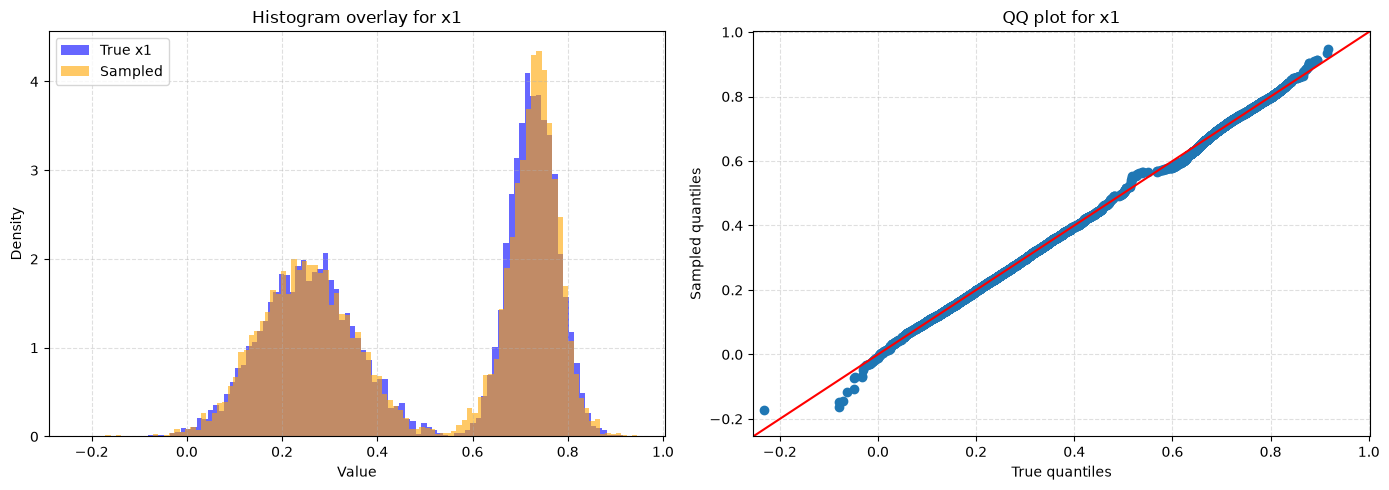

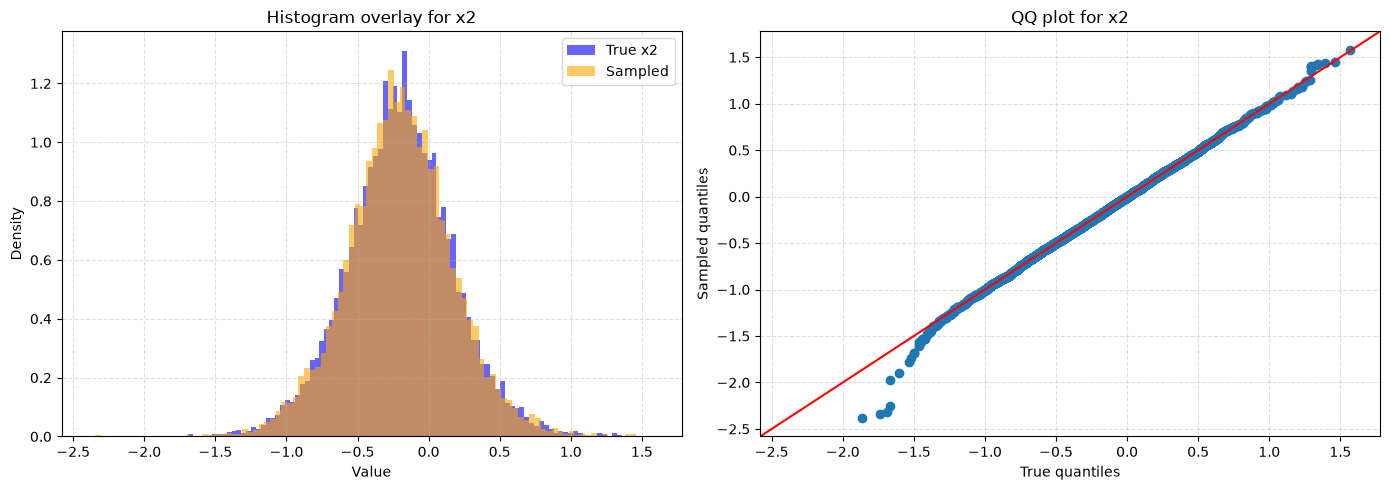

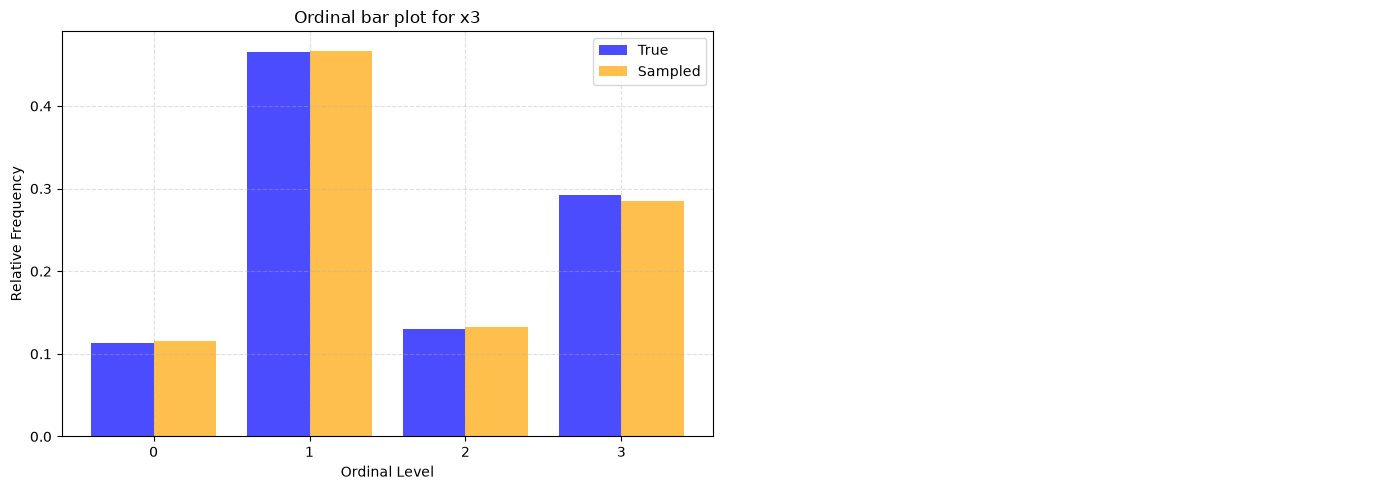

In [12]:
samples, latents = model.sample(number_of_samples=10_000, seed=1)
model.plot_samples_vs_true(test_df, samples)

### Interventional: do(x1 = 0.8)

[INFO] x1: do(x1=0.8)
[INFO] x2: standard logistic latents
[INFO] x3: standard logistic latents


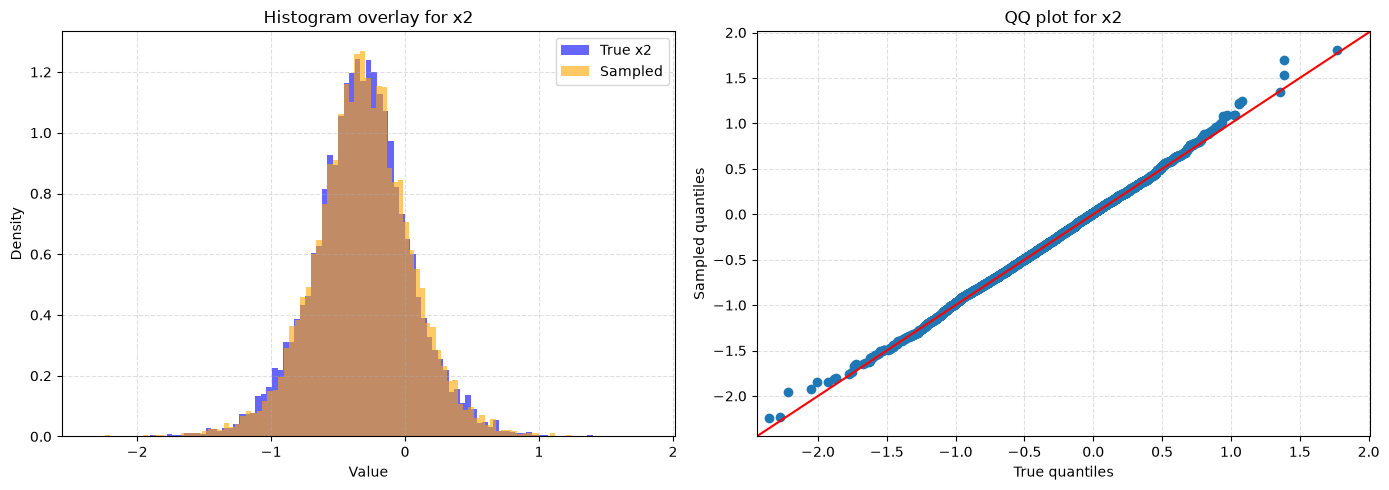

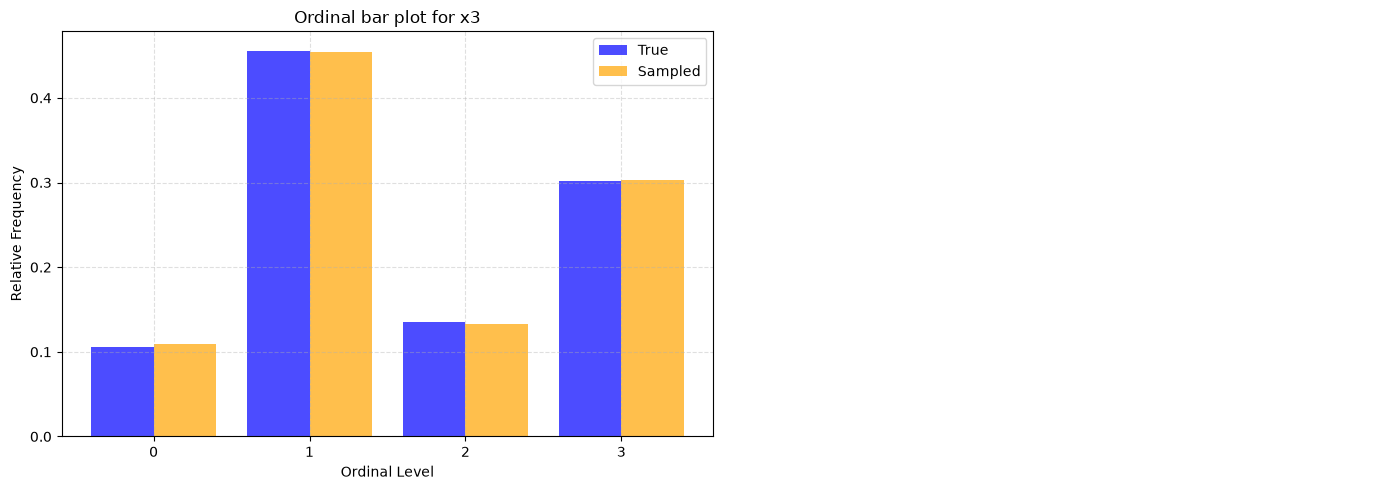

In [13]:
samples_do, _ = model.sample(do_interventions={"x1": 0.8}, seed=2)
truth_do = dgp(10_000, do_x1=0.8, seed=3)
model.plot_samples_vs_true(truth_do, samples_do, variable=["x2", "x3"])

### Counterfactual

*What would `x3` have been for these patients if `x2` had been -0.2?*
Abduction: `get_latent` returns `U` for continuous nodes and the latent interval `[U_lower, U_upper]` of the observed class
for ordinal nodes. The counterfactual of an ordinal node is therefore a distribution over its classes.

In [14]:
obs = test_df.iloc[:5]
u = model.get_latent(obs)
u.round(3)

,x1,x1_U,x2,x2_U,x3,x3_U_lower,x3_U_upper
86525,0.709,0.646,0.060,1.682,0,-inf,-1.781
4024,0.686,0.370,0.626,4.444,3,1.789,inf
4731,0.736,1.177,-0.138,0.750,2,0.439,1.024
46016,0.433,-0.076,-0.372,-1.008,2,0.162,0.748
46674,0.734,1.117,0.056,1.713,1,-1.781,0.635


In [15]:
cf, _ = model.sample(do_interventions={"x2": -0.2}, predefined_latent_samples_df=u, seed=4)
pd.DataFrame(cf["x3"], columns=[f"P(x3_cf={k})" for k in range(4)], index=obs.index).assign(x3_observed=obs["x3"]).round(3)

[INFO] x1: predefined latents x1_U


[INFO] x2: do(x2=-0.2)
[INFO] x3: interval latents (truncated logistic)


,P(x3_cf=0),P(x3_cf=1),P(x3_cf=2),P(x3_cf=3),x3_observed
86525,0.794,0.206,0.000,0.000,0
4024,0.000,0.000,0.000,1.000,3
4731,0.000,0.000,0.904,0.096,2
46016,0.000,0.308,0.692,0.000,2
46674,0.000,0.877,0.123,0.000,1


## Reloading a trained model

Everything is stored in the experiment directory (`configuration.json`, `min_max_scaling.json`, per node
`best_params.npz`, `last_params.npz`, loss and parameter histories).

In [16]:
reloaded = TramDagModel.from_directory("quickstart_experiment")
reloaded.summary()


                                                 TRAM DAG MODEL SUMMARY                                                 

[1] TRAINING METRICS OVERVIEW
------------------------------------------------------------------------------------------------------------------------
     Node       Best Train NLL  Best Val NLL   Last Train NLL  Last Val NLL      Epochs    
      x1           -0.5826        -0.5776         -0.5826        -0.5776          200      
      x2            0.3419         0.3474          0.3419         0.3479          200      
      x3            1.2140         1.2049          1.2141         1.2054          200      
------------------------------------------------------------------------------------------------------------------------

[2] NODE-SPECIFIC DETAILS
------------------------------------------------------------------------------------------------------------------------

                                                        NODE: x1                        

    Θ (20): [-7.8142, -7.3641, -6.9908, -5.8864, -4.9403, -4.1941, -2.9698, -2.1163, -1.4826, -0.5358,  0.2418,  0.7588,
  1.6524,  2.7418,  3.6549,  4.0989,  4.5803,  4.9843,  6.1973,  6.7086]

  [LAST STATE]
    Θ (20): [-59.1395, -44.716 , -35.933 , -24.7527, -16.9713, -11.0003,  -4.5419,  -0.3399,  -0.3336,  -0.3333,  -0.3333,
  -0.3333,  -0.3332,  -0.3332,  -0.3332,  -0.3331,  -0.3326,   3.2129,  35.4772,  60.9326]

  [BEST STATE]
    Θ (20): [-59.1395, -44.716 , -35.933 , -24.7527, -16.9713, -11.0003,  -4.5419,  -0.3399,  -0.3336,  -0.3333,  -0.3333,
  -0.3333,  -0.3332,  -0.3332,  -0.3332,  -0.3331,  -0.3326,   3.2129,  35.4772,  60.9326]
------------------------------------------------------------------------------------------------------------------------

                                                        NODE: x2                                                        
  h(x2 | x1) = SI + ls(x1)

  [INIT STATE]
    Θ (20): [-7.7416e+00, -6.5636e+00, -5.5530e+00, -4.6500e